In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Indefinite Integrals

An integral is the opposite of the derivitive, often referred as the "Anti-Derivitive", as it is it's opposite. What this means is that when you calculate a given integral, you can verify whether it is correct by taking the solution's derivitive and you should return back to the original function.

**The General Rule for Indefinite Integrals**

$$\int f(x)\,dx = F(x) + C$$





This method allows us to calculate the area under a curve in the functions entire domain. To integrate a power we do the following to the function:

$$\int x^n \, dx = \frac{x^{n+1}}{n+1} + C, \quad n \neq -1$$


**Note**
* Where the dx is placed tells you up to what point in the function you should integrate, meaning if the dx is placed at the end you integrate the entire function while a dx placed half way through tells you to integrate part of the function and leave the rest as is.

**Indefinite Integral Properties**
1. You can factor out constant coeficients out of the integral.
$$\int k \, f(x) \, dx = k \int f(x) \, dx$$
2. You can subtract or add two seperate integrals or two functions then integrate will result in the same answer.
$$\int \left[ f(x) + g(x) \right] dx = \int f(x) \, dx + \int g(x) \, dx$$

$$\int \left[ f(x) - g(x) \right] dx = \int f(x) \, dx - \int g(x) \, dx$$

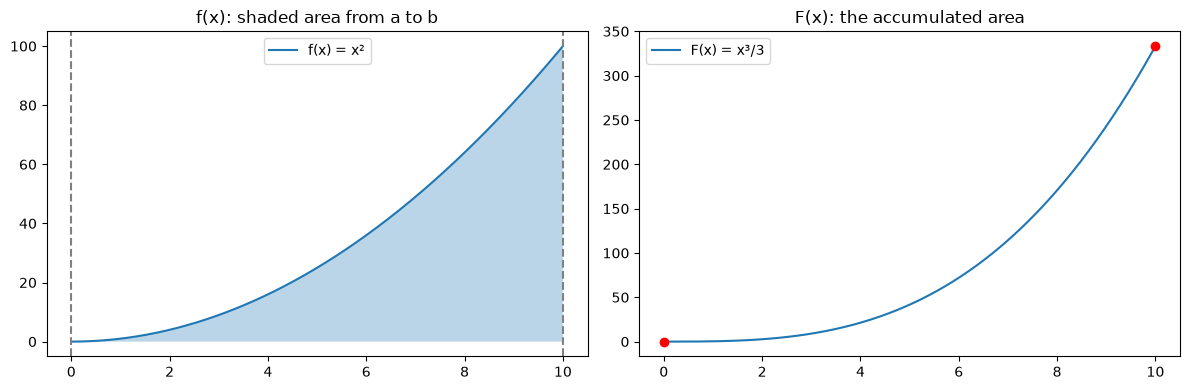

333.3333333333333


In [41]:
def f(x):
    return x**2

def F(x):
    return x**3/3

a, b = 0, 10          # bounds of the area

# use linspace because we there are infinite increasingly small values between each point
x = np.linspace(0, b, 1000)
y = f(x)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Left: f(x) with the area between a and b filled in
sns.lineplot(x=x, y=y, label="f(x) = x²",ax=ax1)
ax1.fill_between(x, y, where=(x >= a) & (x <= b), alpha=0.3)
ax1.axvline(a, linestyle="--", color="grey")
ax1.axvline(b, linestyle="--", color="grey")
ax1.set_title("f(x): shaded area from a to b")
ax1.legend()

# Right: F(x), with the heights at a and b marked
sns.lineplot(x=x, y=F(x), label="F(x) = x³/3",ax=ax2)
ax2.scatter([a, b], [F(a), F(b)], color="red", zorder=3)
ax2.set_title("F(x): the accumulated area")
ax2.legend()

plt.tight_layout()
plt.show()

print(F(b) - F(a))

In [46]:
# lets do a real world example
def car_acc_func(x):
    return 2*x - 5

func_txt = "2x - 5"

# the integral I did by hand
def velocity_func(x):
    return x**2 - 5*x

velocity_func_test = "x**2 - 5x"

# now create the dispalcement - done by hand
def displacement_func(x):
    return x**3/3 - 5*x**2/2 + 3

displacement_func_txt = "x**3/3 - 5*x**2/2 + 3"

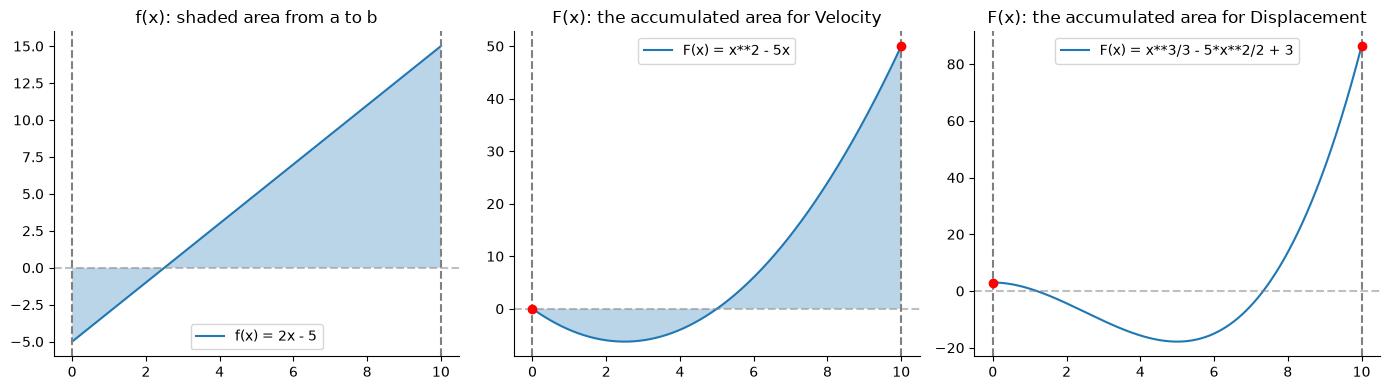

In [47]:

# use linspace because we there are infinite increasingly small values between each point
x = np.linspace(0, 10, 1000)
y = car_acc_func(x)


fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))

# Left: f(x) with the area between a and b filled in
sns.lineplot(x=x, y=y, label=f"f(x) = {func_txt}",ax=ax1)
ax1.fill_between(x, y, where=(x >= a) & (x <= b), alpha=0.3)
ax1.set_title("f(x): shaded area from a to b")
ax1.legend()

# Middle: F(x), with the heights at a and b marked
sns.lineplot(x=x, y=velocity_func(x), label=f"F(x) = {velocity_func_test}",ax=ax2)
ax2.scatter([a, b], [velocity_func(a), velocity_func(b)], color="red", zorder=3)
ax2.fill_between(x, velocity_func(x), where=(x >= a) & (x <= b), alpha=0.3)
ax2.set_title("F(x): the accumulated area for Velocity")
ax2.legend()

# Right: F(x), with the heights at a and b marked
sns.lineplot(x=x, y=displacement_func(x), label=f"F(x) = {displacement_func_txt}",ax=ax3)
ax3.scatter([a, b], [displacement_func(a), displacement_func(b)], color="red", zorder=3)
ax3.set_title("F(x): the accumulated area for Displacement")
ax3.legend()

for ax in fig.axes:
    ax.axhline(y=0,linestyle='--',color='grey',alpha=0.5)
    ax.axvline(a, linestyle="--", color="grey")
    ax.axvline(b, linestyle="--", color="grey")

sns.despine()
plt.tight_layout()
plt.show()

##### Notes

Each graph shows their own data about this car:

1. **Acceleration:** a simple line plot of the car's acceleration over time, $f(x) = 2x - 5$.
2. **Velocity:** the accumulated area under the acceleration curve, $F(x) = x^2 - 5x$. It tells us the car's velocity at each point in time.
3. **Displacement:** the accumulated area under the velocity curve, $F(x) = \frac{x^3}{3} - \frac{5x^2}{2} + 3$. It tells us where the car is at each point in time (it starts at position 3).

What this gives us is that we can choose an interval in time in the x-axis and our functions will return:
1. Acceloration.
2. Total Velocity.
3. Total Displacement.

But how did I get my integral functions? By solving an **initial value problem**: a differential equation *plus* an initial condition. Integrating gives a whole family of solutions (one for each value of $C$), and the initial condition picks out the one that fits.

The steps are quite straightforward:

1. Start with the derivative and the initial condition you are given: $\frac{dy}{dx} = f(x)$ and $y(x_0) = y_0$.
2. Multiply both sides by $dx$ to separate the variables: $dy = f(x)\,dx$.
3. Integrate both sides: $y = F(x) + C$.
4. Plug in the initial condition ($x = x_0$, $y = y_0$).
5. Solve for $C$.
6. Write out the final solution with $C$ substituted in.

**Example:**

$$\frac{dy}{dx} = 2x, \qquad F(0) = 5$$

Multiply both sides by $dx$ to separate the variables:

$$dy = 2x \, dx$$

Integrate both sides:

$$\int dy = \int 2x \, dx$$

$$y = x^2 + C$$

Plug in the initial condition $F(0) = 5$, i.e. $x = 0$, $y = 5$:

$$5 = 0^2 + C$$

$$C = 5$$

**Therefore:**

$$F(x) = x^2 + 5$$

**Example:**

$$\frac{dy}{dx} = 2x, \qquad f(0) = 5$$

Multiply both sides by $dx$ to separate the variables:

$$dy = 2x \, dx$$

Integrate both sides:

$$\int dy = \int 2x \, dx$$

$$y = x^2 + C$$

Solve for $C$ by plugging in the initial condition $f(0) = 5$, i.e. $x = 0$, $y = 5$:

$$5 = 0^2 + C$$

$$C = 5$$

**Therefore:**

$$f(x) = x^2 + 5$$